In [216]:
#%pip install pandas openpyxl seaborn matplotlib

In [217]:
#%pip install openpyxl

In [218]:
#%pip install numpy

In [219]:
import pandas as pd
import openpyxl
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [220]:
df_creditos_saude = pd.read_excel("Base_Case_Credito_Profissionais_Saude.xlsx", sheet_name="base_completa")

## **Visão Geral da tabela**
### conhecendo as colunas e valores

| Coluna             | Tipo     | Conteúdo                                      |
|--------------------|----------|-----------------------------------------------|
| Profissao          | texto    | Médico, Dentista, Enfermeiro, Fisioterapeuta, Outros |
| Tempo_Atuacao_Anos | texto    | 0-2, 3-5, 6-10, 10+                   |
| Faixa_Renda_Mensal | texto    | até 5k, até 10k, até 20k, 20k+        |
| Tipo_Produto       | texto    | Crédito Pessoal, Equipamentos, Capital de Giro |
| Valor_Contrato     | inteiro  | R$ 5.000 a R$ 120.581                         |
| Inadimplente       | booleano | Verdadeiro ou Falso                           |
| Inadimplente_FLAG  | inteiro  | 0 ou 1            |

In [221]:
df_creditos_saude.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Profissao           2000 non-null   str  
 1   Tempo_Atuacao_Anos  2000 non-null   str  
 2   Faixa_Renda_Mensal  2000 non-null   str  
 3   Tipo_Produto        2000 non-null   str  
 4   Valor_Contrato      2000 non-null   int64
 5   Inadimplente        2000 non-null   bool 
 6   Inadimplente_FLAG   2000 non-null   int64
dtypes: bool(1), int64(2), str(4)
memory usage: 95.8 KB


In [222]:
for coluna in df_creditos_saude.columns:
    if coluna == "Valor_Contrato":
        break
    else:
        print(coluna)
        print(df_creditos_saude[coluna].unique())
        print()

Profissao
<StringArray>
['Dentista', 'Enfermeiro', 'Fisioterapeuta', 'Medico', 'Outros']
Length: 5, dtype: str

Tempo_Atuacao_Anos
<StringArray>
['3-5', '10+', '0-2', '6-10']
Length: 4, dtype: str

Faixa_Renda_Mensal
<StringArray>
['5k-10k', '20k+', 'Até 5k', '10k-20k']
Length: 4, dtype: str

Tipo_Produto
<StringArray>
['Equipamentos', 'Credito Pessoal', 'Capital de Giro']
Length: 3, dtype: str



In [223]:
df_creditos_saude["Faixa_Renda_Mensal"] = df_creditos_saude["Faixa_Renda_Mensal"].replace("Até 5k", "até 5k")
df_creditos_saude["Faixa_Renda_Mensal"] = df_creditos_saude["Faixa_Renda_Mensal"].replace("5k-10k", "até 10k")
df_creditos_saude["Faixa_Renda_Mensal"] = df_creditos_saude["Faixa_Renda_Mensal"].replace("10k-20k", "até 20k")


In [224]:
for coluna in df_creditos_saude.columns:
    if coluna == "Valor_Contrato":
        break
    else:
        print(coluna)
        print(df_creditos_saude[coluna].unique())
        print()

Profissao
<StringArray>
['Dentista', 'Enfermeiro', 'Fisioterapeuta', 'Medico', 'Outros']
Length: 5, dtype: str

Tempo_Atuacao_Anos
<StringArray>
['3-5', '10+', '0-2', '6-10']
Length: 4, dtype: str

Faixa_Renda_Mensal
<StringArray>
['até 10k', '20k+', 'até 5k', 'até 20k']
Length: 4, dtype: str

Tipo_Produto
<StringArray>
['Equipamentos', 'Credito Pessoal', 'Capital de Giro']
Length: 3, dtype: str



In [225]:
df_creditos_saude.describe()

,Valor_Contrato,Inadimplente_FLAG
count,2000.000000,2000.000000
mean,49936.894500,0.092000
std,20691.668546,0.289098
min,5000.000000,0.000000
25%,35454.000000,0.000000
50%,49415.500000,0.000000
75%,64341.000000,0.000000
max,120581.000000,1.000000


In [226]:
df_creditos_saude["Valor_Contrato"].min()

np.int64(5000)

In [227]:
df_creditos_saude["Valor_Contrato"].max()

np.int64(120581)

In [228]:
df_creditos_saude["Valor_Contrato"].mean()

np.float64(49936.8945)

In [229]:
df_creditos_ = df_creditos_saude.copy()
df_creditos_ = df_creditos_.reset_index(drop=True)

In [230]:
for indice_linha in range(len(df_creditos_)):
    registro_selecionado = df_creditos_.loc[indice_linha, "Tipo_Produto"]
    if registro_selecionado == "Capital de Giro":
        df_creditos_.at[indice_linha, "PJ"] = True
    else:
        df_creditos_.at[indice_linha, "PJ"] = False

In [231]:
print(len(df_creditos_saude))


2000


### Entre registros filtrados inadimplência, apenas 184 deles correspondem como verdadeiro, ou seja 9.2% de 2000 registros

In [232]:
df_inadimplencia_ = df_creditos_.copy()
df_inadimplencia_ = df_inadimplencia_[df_inadimplencia_["Inadimplente"] == True]
df_inadimplencia_ = df_inadimplencia_.reset_index(drop=True)
#print(len(df_inadimplencia_))
print("Quantidade de Profissionais Inadimplentes:", len(df_inadimplencia_))
print(f"Porcentagem de inadimplêntes: {round(( len(df_inadimplencia_) * 100)/ len(df_creditos_saude),2)}%")


Quantidade de Profissionais Inadimplentes: 184
Porcentagem de inadimplêntes: 9.2%


---

In [233]:
total_registros = len(df_inadimplencia_)
print(total_registros)

184


In [234]:
print((len(df_inadimplencia_)/len(df_creditos_))*100)

9.2


### Para os 184 valores presentes em inadimplência:
- É possível concluir que o tipo de contrato mais possível corresponde a valores solicitados para **Crédito Pessoal**
- Enquanto **Capital de Giro** corresponde a menos de 1/5 

| Crédito Pessoal | Equipamentos | Capital de Giro |
|:---------------:|:------------:|:---------------:|
| 86              | 63           | 35              |
| 46,74%          | 34,24%       | 19,02%          |

In [235]:
lista_tipos = ["Credito Pessoal", "Equipamentos", "Capital de Giro"]
for tipo_produto in lista_tipos:
    contador_tipo = 0
    for linha_contador in range(len(df_inadimplencia_)):
        registro_contador = df_inadimplencia_.loc[linha_contador, "Tipo_Produto"]
        if tipo_produto == registro_contador:
            contador_tipo+=1
    print(tipo_produto)
    print("Quantidade de registros:", contador_tipo)
    print(f"Valor em porcentagem: {round((contador_tipo * 100) / total_registros, 2)}%")
    print()
    

Credito Pessoal
Quantidade de registros: 86
Valor em porcentagem: 46.74%

Equipamentos
Quantidade de registros: 63
Valor em porcentagem: 34.24%

Capital de Giro
Quantidade de registros: 35
Valor em porcentagem: 19.02%



---

### Com base nessa análise, é possível afirmar que:
- a quantidade de inadimplência é bem distribuída entre as profissões, revelando uma diferença mínima entre eles. 
- Apesar disso, Médicos e Dentista tendenciam a ser maioria dentro de inadimplentes.

| Médico          | Dentista     | Fisiote         | Enfermeiro      |  Outros         |
|:---------------:|:------------:|:---------------:|:---------------:|:---------------:|
| 46              | 34           | 33              |   29            |  42             | 
| 25%             | 18,48%       | 17,93%          |   15,76%        |  22,83%         | 


In [236]:
profissoes = ['Dentista', 'Outros', 'Fisioterapeuta', 'Enfermeiro', 'Medico']
for profissao in profissoes:
    contador_prof = 0
    for indice_linha in range(len(df_inadimplencia_)):
        registro = df_inadimplencia_.loc[indice_linha, "Profissao"]
        if profissao == registro:
            contador_prof+=1
    print(profissao)
    print("Quantidade de registros:", contador_prof)
    print(f"Valor em porcentagem: {round((contador_prof * 100)/total_registros,2)}%")
    print()

Dentista
Quantidade de registros: 34
Valor em porcentagem: 18.48%

Outros
Quantidade de registros: 42
Valor em porcentagem: 22.83%

Fisioterapeuta
Quantidade de registros: 33
Valor em porcentagem: 17.93%

Enfermeiro
Quantidade de registros: 29
Valor em porcentagem: 15.76%

Medico
Quantidade de registros: 46
Valor em porcentagem: 25.0%



---

### Fica comprovado que profissionais com **renda mensal** menor que 10k, representam maior número de inadimplentes. 
- É evidênciado que a renda mensal tem impacto direto na inadimplência do profissional.

| Até 5k          | 5k-10k       | 10k-20k         | 20k+            | até 10k |
|:---------------:|:------------:|:---------------:|:---------------:|:---------------:|
| 67              | 60           | 35              |   22            | 127 |
| 36,41%          | 32,61%       | 19,02%          |   11,96%        |69,02%|



In [258]:
renda_mensal = ['até 5k', 'até 10k', 'até 20k', '20k+']
for renda in renda_mensal:
    contador_renda = 0
    for indice_linha in range(len(df_inadimplencia_)):
        registro = df_inadimplencia_.loc[indice_linha, "Faixa_Renda_Mensal"]
        if renda == registro:
            contador_renda+=1
    print(renda)
    print("Quantidade de registros:", contador_renda)
    print(f"Valor em porcentagem: {round((contador_renda * 100)/ total_registros,2)}%")
    print()

até 5k
Quantidade de registros: 67
Valor em porcentagem: 145.65%

até 10k
Quantidade de registros: 60
Valor em porcentagem: 130.43%

até 20k
Quantidade de registros: 35
Valor em porcentagem: 76.09%

20k+
Quantidade de registros: 22
Valor em porcentagem: 47.83%



---

## É evidenciado que quanto menor o tempo de atuação profissional, maior é a chance 

In [259]:
anos_atuacao = ['3-5', '0-2', '10+', '6-10']
for tempo_atucao in anos_atuacao:
    contador = 0
    for indice_linha in range(len(df_inadimplencia_)):
        registro = df_inadimplencia_.loc[indice_linha, "Tempo_Atuacao_Anos"]
        if tempo_atucao == registro:
            contador+=1
    print(tempo_atucao)
    print("Quantidade de registros:", contador)
    print(f"Valor em porcentagem: {round((contador * 100)/ total_registros,2)}%")
    print()

3-5
Quantidade de registros: 49
Valor em porcentagem: 106.52%

0-2
Quantidade de registros: 69
Valor em porcentagem: 150.0%

10+
Quantidade de registros: 29
Valor em porcentagem: 63.04%

6-10
Quantidade de registros: 37
Valor em porcentagem: 80.43%



---

### Pessoas que atuem de 5 anos para menos, ocupam mais de 60% dos inadimplentes, mostrando padrão de usuário muito forte em relação a inamdiplência.
- Ainda em cima disso, a quantidade de profissionais que até 2 anos e recebem no máximo 5k, equivalem a 38% em comparação a outros períodos de atuação, ocupanda maior parte dessa faixa  

In [260]:
linhas = []

for tempo_atuacao in anos_atuacao:
    df_temp_profissao = df_inadimplencia_[df_inadimplencia_["Tempo_Atuacao_Anos"] == tempo_atuacao].copy()
    df_temp_profissao = df_temp_profissao.reset_index(drop=True)
    total_registros = len(df_temp_profissao)

    for renda in renda_mensal:
        contador_renda = 0
        for indice_linha in range(len(df_temp_profissao)):
            renda_selecionada = df_temp_profissao.loc[indice_linha, "Faixa_Renda_Mensal"]
            if renda == renda_selecionada:
                contador_renda += 1

        linhas.append({
            "Tempo_Atuacao": tempo_atuacao,
            "Renda": renda,
            "Quant_Registros": contador_renda,
            "%": round((contador_renda * 100) / total_registros, 2),
        })

df_atuacao_renda = pd.DataFrame(linhas)

for temp_atuacao in anos_atuacao:
    soma_reg = df_atuacao_renda[df_atuacao_renda["Tempo_Atuacao"] == temp_atuacao]["Quant_Registros"].sum()
    print(df_atuacao_renda[df_atuacao_renda["Tempo_Atuacao"] == temp_atuacao])
    print("Total de registros:", soma_reg)
    print()

  Tempo_Atuacao    Renda  Quant_Registros      %
0           3-5   até 5k               18  36.73
1           3-5  até 10k               18  36.73
2           3-5  até 20k                8  16.33
3           3-5     20k+                5  10.20
Total de registros: 49

  Tempo_Atuacao    Renda  Quant_Registros      %
4           0-2   até 5k               26  37.68
5           0-2  até 10k               22  31.88
6           0-2  até 20k               15  21.74
7           0-2     20k+                6   8.70
Total de registros: 69

   Tempo_Atuacao    Renda  Quant_Registros      %
8            10+   até 5k               11  37.93
9            10+  até 10k               11  37.93
10           10+  até 20k                4  13.79
11           10+     20k+                3  10.34
Total de registros: 29

   Tempo_Atuacao    Renda  Quant_Registros      %
12          6-10   até 5k               12  32.43
13          6-10  até 10k                9  24.32
14          6-10  até 20k             

---

In [261]:
df_inadimplencia_ = df_inadimplencia_.drop("Inadimplente_FLAG", axis=1)
df_inadimplencia_ = df_inadimplencia_.sort_values(by=['Profissao', 'Tempo_Atuacao_Anos', 'Tipo_Produto'])
df_inadimplencia_ = df_inadimplencia_.reset_index(drop=True)
df_inadimplencia_

,Profissao,Tempo_Atuacao_Anos,Faixa_Renda_Mensal,Tipo_Produto,Valor_Contrato,Inadimplente,PJ
0,Dentista,0-2,até 5k,Capital de Giro,37844,True,True
1,Dentista,0-2,até 10k,Capital de Giro,91988,True,True
2,Dentista,0-2,até 5k,Credito Pessoal,39748,True,False
3,Dentista,0-2,até 20k,Credito Pessoal,55661,True,False
4,Dentista,0-2,até 5k,Credito Pessoal,67285,True,False
...,...,...,...,...,...,...,...
179,Outros,6-10,até 20k,Credito Pessoal,40839,True,False
180,Outros,6-10,até 5k,Equipamentos,63818,True,False
181,Outros,6-10,até 10k,Equipamentos,29478,True,False
182,Outros,6-10,até 10k,Equipamentos,73120,True,False


In [262]:
contador = 0
for indice_linha in range(len(df_inadimplencia_)):
    pj_ver = df_inadimplencia_.loc[indice_linha, "PJ"]
    
    if pj_ver:
        contador+=1
print("PJ inadimplentes")
print(f"Quantidade: {contador}")
print(f"Porcentagem: {round(( contador * 100)/ len(df_inadimplencia_),2)}%")

PJ inadimplentes
Quantidade: 35
Porcentagem: 19.02%


In [263]:
linhas = []

for profissao in profissoes:
    df_temp_profissao = df_inadimplencia_[df_inadimplencia_["Profissao"] == profissao].copy()
    df_temp_profissao = df_temp_profissao.reset_index(drop=True)
    total_registros = len(df_temp_profissao)

    contador_tipo = 0
    for indice_linha in range(len(df_temp_profissao)):
        registro_pj = df_temp_profissao.loc[indice_linha, "PJ"]
        if registro_pj:
            contador_tipo += 1

    linhas.append({
        "Profissao": profissao,
        "Total": total_registros,
        "Quant_PJ": contador_tipo,
        "%": round((contador_tipo * 100) / total_registros, 2),
    })

df_profissionais = pd.DataFrame(linhas)

df_profissionais

,Profissao,Total,Quant_PJ,%
0,Dentista,34,7,20.59
1,Outros,42,11,26.19
2,Fisioterapeuta,33,5,15.15
3,Enfermeiro,29,4,13.79
4,Medico,46,8,17.39


In [264]:
df_pjs = df_inadimplencia_[df_inadimplencia_["PJ"] == True].copy()
df_pjs = df_pjs.reset_index(drop=True)
porcentagem_pj_inadimplente = round((len(df_inadimplencia_[df_inadimplencia_["PJ"] == True]) * 100) / len(df_creditos_[df_creditos_["PJ"] == True]), 2)
print(f"PJs na base: {len(df_creditos_[df_creditos_["PJ"] == True])}")
print(f"PJs inadimplentes: {len(df_inadimplencia_[df_inadimplencia_["PJ"] == True])}")
print(f"Porcentagem de pj inadimplentes: {porcentagem_pj_inadimplente}%")

contador = 0
for indice_linha in range(len(df_pjs)):
    registro_pj = df_pjs.loc[indice_linha, "Faixa_Renda_Mensal"]
    if registro_pj == "até 5k" or registro_pj == "até 10k":
        contador+=1
print(f"Quant. PJ recebem < 10k: {contador}")
contador_renda = 0
for indice_linha in range(len(df_pjs)):
    registro_pj = df_pjs.loc[indice_linha, "Tempo_Atuacao_Anos"]
    if registro_pj == "0-2" or registro_pj == "3-5":
        contador_renda+=1
print(f"Quant. PJ atuam a menos de 5 anos: {contador_renda}")
print(f"Porcentagem: {round((contador_renda * 100)/len(df_pjs))}%")

PJs na base: 390
PJs inadimplentes: 35
Porcentagem de pj inadimplentes: 8.97%
Quant. PJ recebem < 10k: 24
Quant. PJ atuam a menos de 5 anos: 28
Porcentagem: 80%


---

### **Aqui fica comprovado que em 80% das profissões:**
- a maioria da inadimplência vem da solicitação do **Crédito Pessoal**, exceto em profissionais Médicos

In [265]:
linhas = []

for profissao in profissoes:
    df_temp_profissao = df_inadimplencia_[df_inadimplencia_["Profissao"] == profissao].copy()
    df_temp_profissao = df_temp_profissao.reset_index(drop=True)
    total_registros = len(df_temp_profissao)

    for tipo_contrato in lista_tipos:
        contador_tipo = 0
        for indice_linha in range(len(df_temp_profissao)):
            registro_tipo = df_temp_profissao.loc[indice_linha, "Tipo_Produto"]
            if tipo_contrato == registro_tipo:
                contador_tipo += 1

        linhas.append({
            "Profissao": profissao,
            "Tipo_Contrato": tipo_contrato,
            "Quant. Registros": contador_tipo,
            "%": round((contador_tipo * 100) / total_registros, 2),
        })

df_profissionais = pd.DataFrame(linhas)

for profissao in profissoes:
    print(df_profissionais[df_profissionais["Profissao"] == profissao])
    print()

  Profissao    Tipo_Contrato  Quant. Registros      %
0  Dentista  Credito Pessoal                14  41.18
1  Dentista     Equipamentos                13  38.24
2  Dentista  Capital de Giro                 7  20.59

  Profissao    Tipo_Contrato  Quant. Registros      %
3    Outros  Credito Pessoal                20  47.62
4    Outros     Equipamentos                11  26.19
5    Outros  Capital de Giro                11  26.19

        Profissao    Tipo_Contrato  Quant. Registros      %
6  Fisioterapeuta  Credito Pessoal                15  45.45
7  Fisioterapeuta     Equipamentos                13  39.39
8  Fisioterapeuta  Capital de Giro                 5  15.15

     Profissao    Tipo_Contrato  Quant. Registros      %
9   Enfermeiro  Credito Pessoal                19  65.52
10  Enfermeiro     Equipamentos                 6  20.69
11  Enfermeiro  Capital de Giro                 4  13.79

   Profissao    Tipo_Contrato  Quant. Registros      %
12    Medico  Credito Pessoal            

---

# **Gráficos** 

### Quantidade de Inadimplentes - PIZZA

In [ ]:
df_inadimplencia_ = df_creditos_.copy()
df_inadimplencia_ = df_inadimplencia_[df_inadimplencia_["Inadimplente"] == True]
df_inadimplencia_ = df_inadimplencia_.reset_index(drop=True)
#print(len(df_inadimplencia_))
print("Quantidade de Profissionais Inadimplentes:", len(df_inadimplencia_))
print(f"Porcentagem de inadimplêntes: {round(( len(df_inadimplencia_) * 100)/ len(df_creditos_saude),2)}%")
print()


Quantidade de Profissionais Inadimplentes: 184
Porcentagem de inadimplêntes: 9.2%

Lucro esperado: R$ 99873789
Saldo perdido: R$ 9367548
Lucro final: R$ 90506241


In [267]:
lucro_esperado = df_creditos_saude["Valor_Contrato"].sum()
perda = df_inadimplencia_["Valor_Contrato"].sum()
lucro_final = df_creditos_["Valor_Contrato"].sum() - (df_inadimplencia_["Valor_Contrato"].sum())
print(f"Lucro Esperado: R$ {lucro_esperado}")
print(f"Perda: R$ {perda}")
print(f"Lucro Final: R$ {lucro_final}")

Lucro Esperado: R$ 99873789
Perda: R$ 9367548
Lucro Final: R$ 90506241


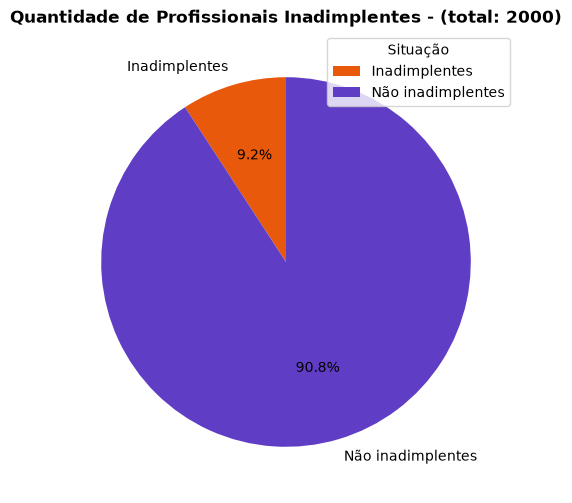

In [268]:
tamanhos = [len(df_inadimplencia_), (len(df_creditos_) - len(df_inadimplencia_))]
labels = ["Inadimplentes", "Não inadimplentes"]

plt.figure(figsize=(6,6))
plt.pie(
    tamanhos,
    labels=labels,
    colors=["#e8590c", "#5f3dc4"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    f"Quantidade de Profissionais Inadimplentes - (total: {len(df_creditos_)})",
    fontweight="bold"
)
plt.legend(title="Situação", loc="upper right")
plt.show()

## Quantidade de profissionais - Coluna Empilhada

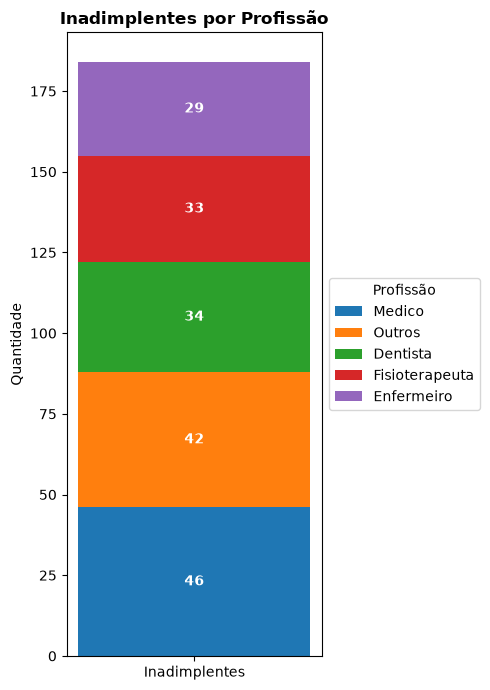

In [269]:

contagem = df_inadimplencia_["Profissao"].value_counts().head(5)

fig, ax = plt.subplots(figsize=(5, 7))

base = 0
for profissao, qtd in contagem.items():
    ax.bar("Inadimplentes", qtd, bottom=base, label=profissao)
    ax.text("Inadimplentes", base + qtd / 2, qtd,
            ha="center", va="center", color="white", fontweight="bold")
    base += qtd

ax.set_title("Inadimplentes por Profissão", fontweight="bold")
ax.set_ylabel("Quantidade")
ax.legend(title="Profissão", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### Quantidade dos Tipos de Contratos - Barras Horizontais

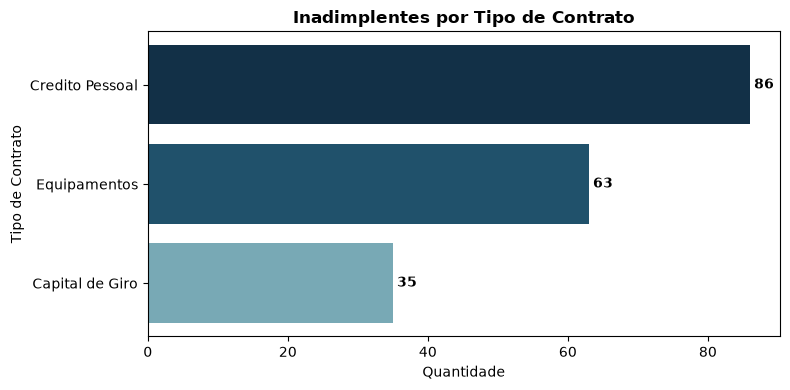

In [270]:

contagem = df_inadimplencia_["Tipo_Produto"].value_counts()

fig, ax = plt.subplots(figsize=(8, 4))

barras = ax.barh(contagem.index, contagem.values, color=["#123047", "#20516B", "#78A9B5"])
ax.invert_yaxis()  # maior categoria no topo

# Valores ao lado de cada barra
ax.bar_label(barras, padding=3, fontweight="bold")

ax.set_title("Inadimplentes por Tipo de Contrato", fontweight="bold")
ax.set_xlabel("Quantidade")
ax.set_ylabel("Tipo de Contrato")
plt.tight_layout()
plt.show()

### Quantidade de tempo de atuação em inadimplentes - Barras

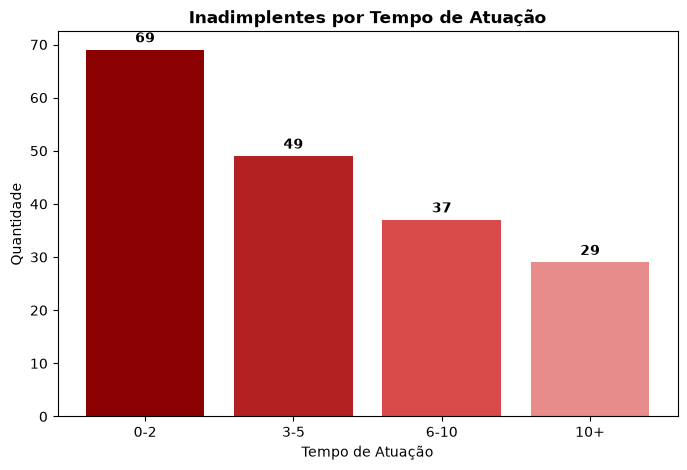

In [271]:
contagem = df_inadimplencia_["Tempo_Atuacao_Anos"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(contagem.index.astype(str), contagem.values, color=["#8B0000", "#B22222", "#D94A4A", "#E88B8B"])

# Valores acima de cada barra
ax.bar_label(barras, padding=3, fontweight="bold")

ax.set_title("Inadimplentes por Tempo de Atuação", fontweight="bold")
ax.set_xlabel("Tempo de Atuação")
ax.set_ylabel("Quantidade")
plt.show()

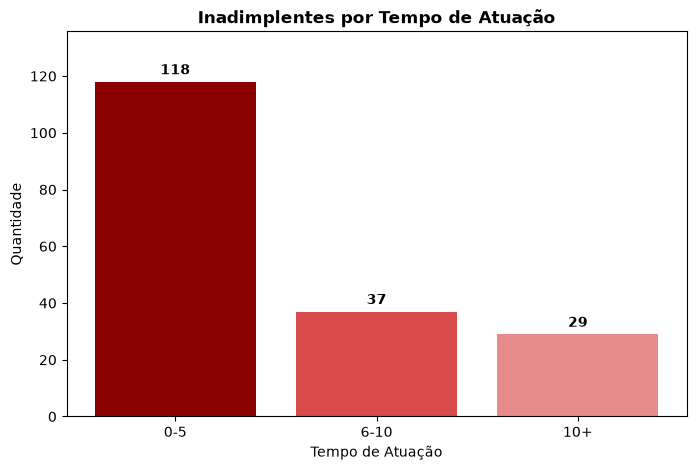

In [272]:
contagem = [118, 37, 29]

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(["0-5", "6-10", "10+"], contagem, color=["#8B0000", "#D94A4A", "#E88B8B"])

# Valores acima de cada barra
ax.bar_label(barras, padding=3, fontweight="bold")

ax.set_title("Inadimplentes por Tempo de Atuação", fontweight="bold")
ax.set_xlabel("Tempo de Atuação")
ax.set_ylabel("Quantidade")
ax.set_ylim(0, max(contagem) * 1.15)  # espaço para o rótulo da maior barra
plt.show()

### Renda Mensal dentro dos Inadimplentes - Barras

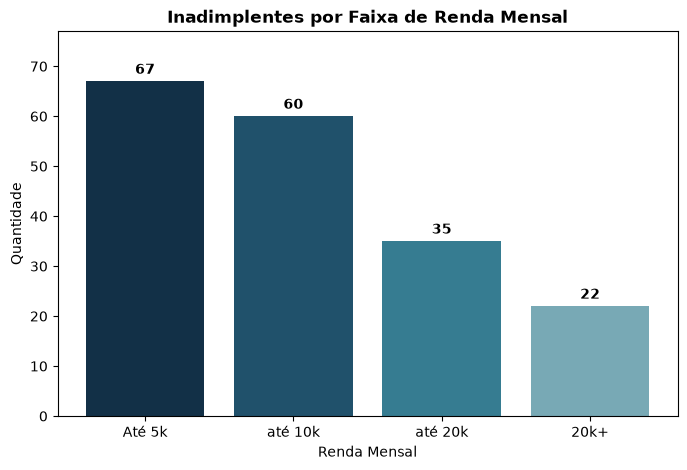

In [273]:
faixas = ['Até 5k', 'até 10k', 'até 20k', '20k+']
contagem = df_inadimplencia_["Faixa_Renda_Mensal"].value_counts()  

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(faixas, contagem, color=["#123047", "#20516B", "#367C91", "#78A9B5"])
ax.bar_label(barras, padding=3, fontweight="bold")

ax.set_title("Inadimplentes por Faixa de Renda Mensal", fontweight="bold")
ax.set_xlabel("Renda Mensal")
ax.set_ylabel("Quantidade")
ax.set_ylim(0, max(contagem) * 1.15)
plt.show()

### Relação de Renda Mensal com Tempo de Atuação,

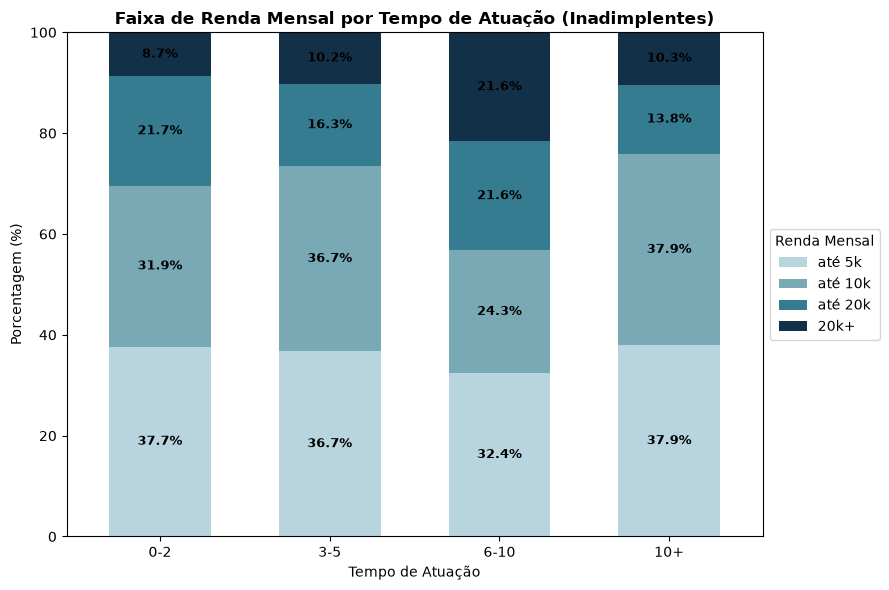

In [274]:
import matplotlib.pyplot as plt

anos_atuacao = ["0-2","3-5", "6-10", "10+"]  # ordem cronológica

tabela = (
    df_atuacao_renda
    .pivot(index="Tempo_Atuacao", columns="Renda", values="%")
    .reindex(index=anos_atuacao, columns=renda_mensal)
)

cores = ["#B8D5DF", "#78A9B5", "#367C91", "#123047"]

fig, ax = plt.subplots(figsize=(9, 6))
tabela.plot(kind="bar", stacked=True, ax=ax, color=cores, width=0.6)

for container in ax.containers:
    rotulos = [f"{v:.1f}%" if v > 0 else "" for v in container.datavalues]
    ax.bar_label(container, labels=rotulos, label_type="center",
                 color="black", fontweight="bold", fontsize=9)

ax.set_title("Faixa de Renda Mensal por Tempo de Atuação (Inadimplentes)", fontweight="bold")
ax.set_xlabel("Tempo de Atuação")
ax.set_ylabel("Porcentagem (%)")
ax.set_ylim(0, 100)
ax.legend(title="Renda Mensal", loc="center left", bbox_to_anchor=(1, 0.5))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

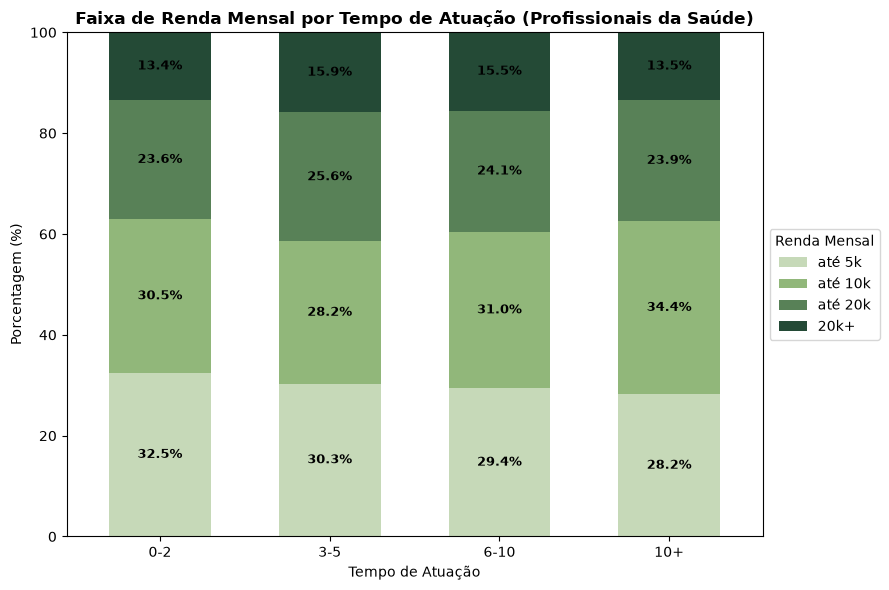

In [275]:
import pandas as pd
import matplotlib.pyplot as plt

anos_atuacao = ["0-2", "3-5", "6-10", "10+"]
renda_mensal = ['até 5k', 'até 10k', 'até 20k', '20k+']  # ajuste conforme os seus valores

# Porcentagem de cada faixa de renda dentro de cada tempo de atuação (cada coluna soma 100%)
tabela = (
    pd.crosstab(
        df_creditos_saude["Tempo_Atuacao_Anos"],
        df_creditos_saude["Faixa_Renda_Mensal"],
        normalize="index"
    )
    .mul(100)
    .round(2)
    .reindex(index=anos_atuacao, columns=renda_mensal)
)

cores = ["#C6D9B8", "#91B77A", "#588157", "#244A36"]

fig, ax = plt.subplots(figsize=(9, 6))
tabela.plot(kind="bar", stacked=True, ax=ax, color=cores, width=0.6)

for container in ax.containers:
    rotulos = [f"{v:.1f}%" if v > 0 else "" for v in container.datavalues]
    ax.bar_label(container, labels=rotulos, label_type="center",
                 color="black", fontweight="bold", fontsize=9)

ax.set_title("Faixa de Renda Mensal por Tempo de Atuação (Profissionais da Saúde)", fontweight="bold")
ax.set_xlabel("Tempo de Atuação")
ax.set_ylabel("Porcentagem (%)")
ax.set_ylim(0, 100)
ax.legend(title="Renda Mensal", loc="center left", bbox_to_anchor=(1, 0.5))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Relação da Renda Mensal e Tempo de Atuação pela Taxa de Inadimplência - Heatmap

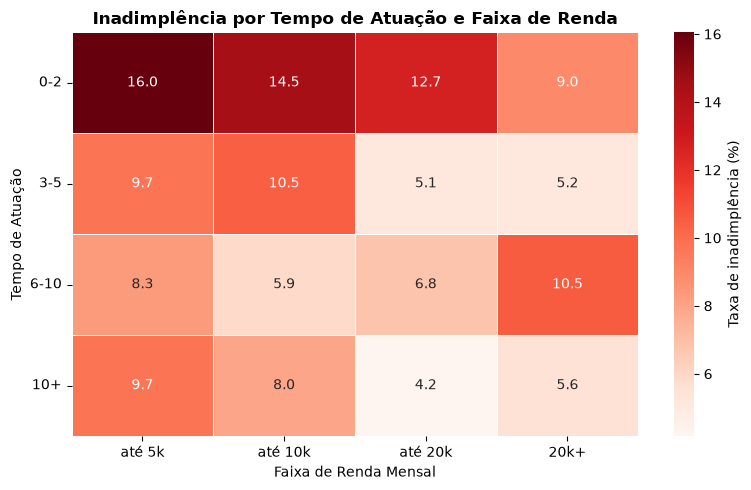

In [276]:

anos_atuacao = ["0-2", "3-5", "6-10", "10+"]
renda_mensal = ["até 5k", "até 10k", "até 20k", "20k+"] 


taxa = (
    df_creditos_saude
    .pivot_table(
        index="Tempo_Atuacao_Anos",
        columns="Faixa_Renda_Mensal",
        values="Inadimplente_FLAG",
        aggfunc="mean"
    )
    .mul(100)
    .reindex(index=anos_atuacao, columns=renda_mensal)
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    taxa,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "Taxa de inadimplência (%)"},
    ax=ax
)

ax.set_title("Inadimplência por Tempo de Atuação e Faixa de Renda", fontweight="bold")
ax.set_xlabel("Faixa de Renda Mensal")
ax.set_ylabel("Tempo de Atuação")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Visualização do lucro

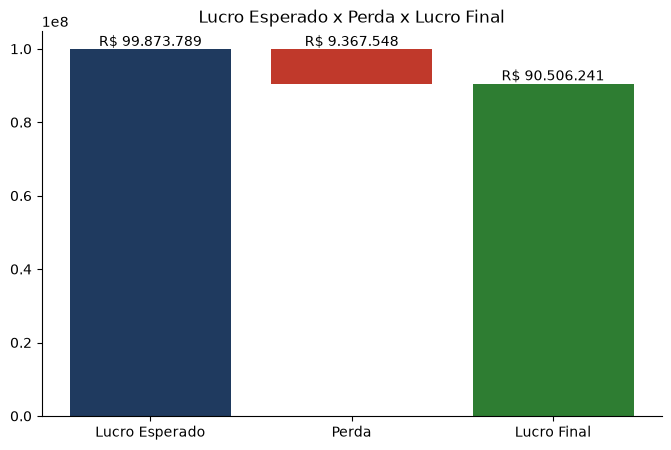

In [279]:
import matplotlib.pyplot as plt

valores = [lucro_esperado, perda, lucro_final]
topos = [lucro_esperado, lucro_esperado, lucro_final]

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar("Lucro Esperado", lucro_esperado, color="#1F3A5F")
ax.bar("Perda", perda, bottom=lucro_esperado - perda, color="#C0392B")
ax.bar("Lucro Final", lucro_final, color="#2E7D32")

for i, (v, t) in enumerate(zip(valores, topos)):
    ax.text(i, t, f"R$ {v:,.0f}".replace(",", "."), ha="center", va="bottom")

ax.set_title("Lucro Esperado x Perda x Lucro Final")
ax.spines[["top", "right"]].set_visible(False)
plt.show()